# 10 · Final comparison and results summary
Collects every metric file produced by notebooks 04–09 into one table and writes `reports/metrics.md`.

In [1]:
import sys; sys.path.insert(0, "..")
import os, warnings, logging; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

def rd(name):
    p = OUT_DIR / name
    return pd.read_csv(p) if p.exists() else None
mode = json.load(open(OUT_DIR / "data_mode.json"))["data_mode"]
print("DATA MODE:", mode.upper())

DATA MODE: SYNTHETIC


## Point-forecast accuracy (28-day test window)

In [2]:
acc = pd.concat([x for x in [rd("metrics_baselines.csv"), rd("metrics_lgbm.csv"), rd("metrics_tft.csv")] if x is not None])
acc = acc.drop_duplicates(["model", "scope"]).sort_values(["scope", "WAPE"]).reset_index(drop=True)
acc

,model,n_series,WAPE,RMSSE,scope
0,lgbm,600,0.6699,0.8091,all series
1,ma28,600,0.7037,0.8428,all series
2,naive,600,0.8764,1.0720,all series
3,snaive,600,0.9299,1.1651,all series
4,lgbm,40,0.4834,0.8345,top 40 series
5,ma28,40,0.5171,0.8927,top 40 series
6,prophet,40,0.5264,0.8915,top 40 series
7,naive,40,0.6603,1.1249,top 40 series
8,snaive,40,0.7213,1.2373,top 40 series


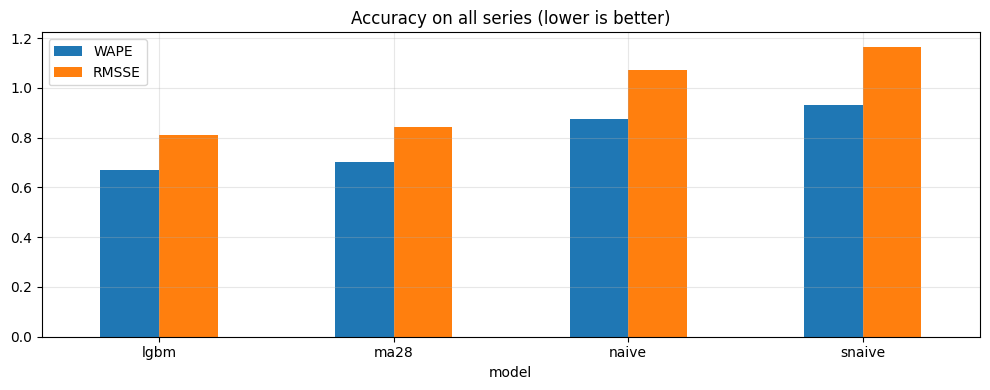

In [3]:
sub = acc[acc.scope == "all series"].set_index("model")[["WAPE", "RMSSE"]]
sub.plot.bar(title="Accuracy on all series (lower is better)"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "10_model_comparison.png", dpi=120); plt.show()

## Intervals, reconciliation, inventory — all headline numbers

In [4]:
iv, rec, cost = rd("metrics_intervals.csv"), rd("metrics_reconciliation.csv"), pd.read_csv(OUT_DIR / "cost_comparison.csv")
display(iv); display(rec); display(cost)

,interval,target,coverage,avg_width
0,80% raw,0.8,0.8564,3.6641
1,80% calibrated,0.8,0.8564,3.6641
2,90% raw,0.9,0.9387,4.5969
3,90% calibrated,0.9,0.9387,4.5969


,level,MinT reconciled,base (unreconciled),bottom-up
0,total,0.0518,0.0745,0.0419
1,state,0.0647,0.0777,0.0546
2,store,0.0865,0.0963,0.0789
3,item-store,0.6801,0.6699,0.6699


,policy,holding_cost,stockout_cost,total_cost,purchase_spend,units_short,units_left,fill_rate,cost_vs_B_%
0,A last-week sales,1871.95,16102.47,17974.42,73426.70,5678.0,5783.0,0.81,32.36
1,B forecast mean,1191.25,12388.75,13579.99,71171.35,4400.0,3437.0,0.85,0.00
2,C optimised,3220.50,2828.47,6048.98,102616.45,939.0,13109.0,0.97,-55.46
3,"D optimised, B's budget",1079.76,12825.50,13905.26,71159.80,4558.0,3598.0,0.85,2.40


In [5]:
def md(df): return df.to_markdown(index=False, floatfmt=".4f")
note = ("> **Data mode: SYNTHETIC.** These numbers validate the pipeline on an M5-shaped stand-in dataset. "
        "Re-run all notebooks on the real M5 files and replace this file before presenting.\n\n") if mode == "synthetic" else ""
best = acc[acc.scope == "all series"].sort_values("WAPE").iloc[0]
B, C = cost.set_index("policy").loc["B forecast mean"], cost.set_index("policy").loc["C optimised"]
text = f"""# Results summary

{note}## Point forecast accuracy (test = last 28 days)
{md(acc)}

Best model on all series: **{best.model}** (WAPE {best.WAPE:.3f}, RMSSE {best.RMSSE:.3f}).

## Prediction intervals (coverage vs target)
{md(iv)}

## Hierarchical reconciliation (WAPE by level)
{md(rec)}

## Inventory policies replayed on 4 test weeks
{md(cost)}

Optimised policy C vs forecast-mean policy B: total cost {C.total_cost:,.0f} vs {B.total_cost:,.0f}
({(C.total_cost / B.total_cost - 1) * 100:+.0f}%), fill rate {C.fill_rate:.1%} vs {B.fill_rate:.1%}, at purchase spend
{C.purchase_spend:,.0f} vs {B.purchase_spend:,.0f}.
"""
(ROOT / "reports").mkdir(exist_ok=True); open(ROOT / "reports" / "metrics.md", "w").write(text); print(text[:600])

# Results summary

> **Data mode: SYNTHETIC.** These numbers validate the pipeline on an M5-shaped stand-in dataset. Re-run all notebooks on the real M5 files and replace this file before presenting.

## Point forecast accuracy (test = last 28 days)
| model   |   n_series |   WAPE |   RMSSE | scope         |
|:--------|-----------:|-------:|--------:|:--------------|
| lgbm    |        600 | 0.6699 |  0.8091 | all series    |
| ma28    |        600 | 0.7037 |  0.8428 | all series    |
| naive   |        600 | 0.8764 |  1.0720 | all series    |
| snaive  |        600 | 0.9299 |  1.1651 | all se
